### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
34.2% Sports & Leisure followed by a joint 0.8%:
Beauty                                     
Handmade Clothing, Shoes & Accessories     
Bath & Body                                
Birthday Gifts 


1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

Luxury Food & Drink                    4.547570
Grocery                                4.469061
Laptop Accessories                     4.449600
Health & Personal Care                 4.439649
Arts & Crafts                          4.432663    


In [39]:
# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [41]:

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

# Preview the data
print("\nFirst 5 rows:")
print(df.head())

# Frequency table for the 'category' column
category_freq = df['category'].value_counts()
print("\nTop Product Categories:\n", category_freq)

# Top 5 most listed product categories


# Group by category and calculate average star rating
category_avg_rating = df.groupby('category')['stars'].mean().sort_values(ascending=False)

# Display top 10 categories
print("🔥 Top 10 Product Categories by Average Star Rating:")
print(category_avg_rating.head(10))




Dataset Shape: (2443651, 9)

Column Names: ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

First 5 rows:
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  1

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

/var/folders/ck/t8ktvnl92454zslcr12m5v9w0000gn/T/ipykernel_55074/1163604896.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index[:top_n], y=category_counts.values[:top_n], palette='viridis')


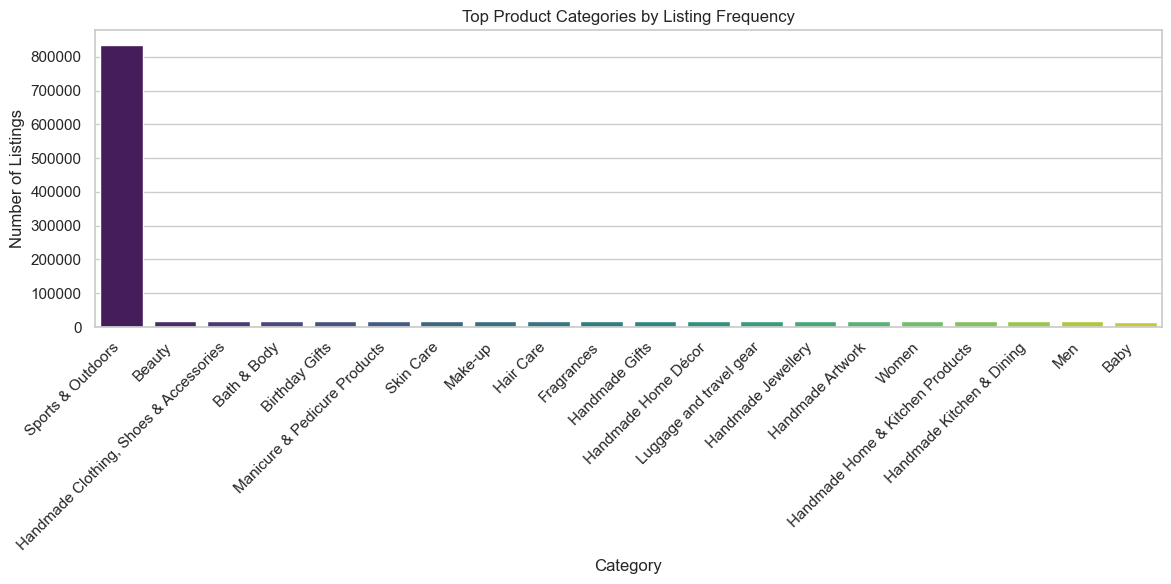

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set(style="whitegrid")

# Plot top 20 categories (or fewer if needed)
top_n = 20
plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.index[:top_n], y=category_counts.values[:top_n], palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Top Product Categories by Listing Frequency')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()


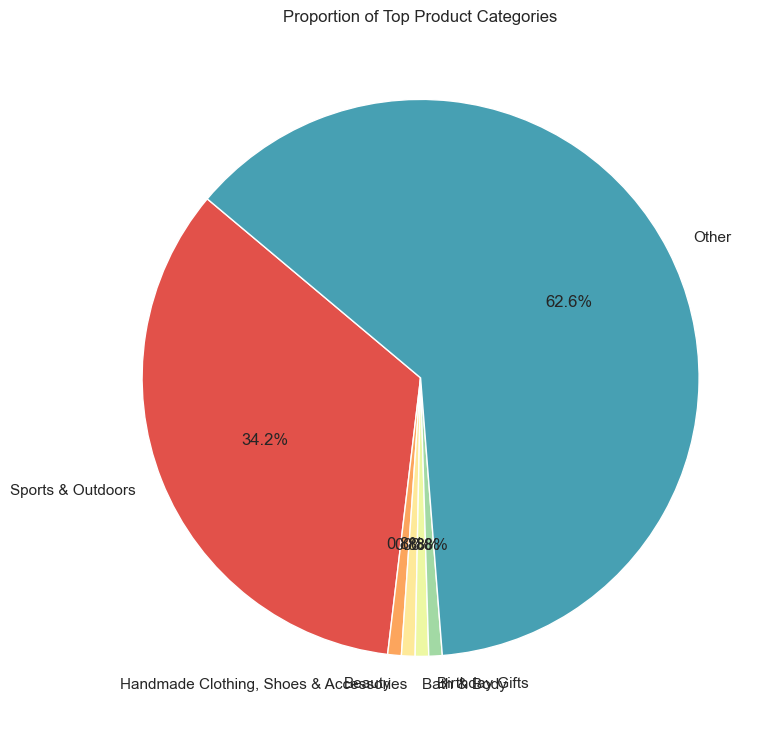

In [43]:
# Select top categories (you can adjust this number)
top_n = 5
top_categories = category_counts.head(top_n)
other_total = category_counts.iloc[top_n:].sum()

# Combine top categories with 'Other'
labels = list(top_categories.index) + ['Other']
values = list(top_categories.values) + [other_total]

# Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('Spectral', len(labels)))
plt.title('Proportion of Top Product Categories')
plt.tight_layout()
plt.show()


In [10]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# Ensure 'price' is numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Drop missing or invalid price entries
df_clean = df.dropna(subset=['price'])

# Calculate centrality measures
mean_price = df_clean['price'].mean()
median_price = df_clean['price'].median()
mode_price = df_clean['price'].mode().iloc[0] if not df_clean['price'].mode().empty else np.nan

# Display results
print(f"Mean Price: £{mean_price:.2f}")
print(f"Median Price: £{median_price:.2f}")
print(f"Mode Price: £{mode_price:.2f}")


Mean Price: £89.24
Median Price: £19.09
Mode Price: £9.99


Insights & Business Implications from Measures of Centrality

Mean Price (£89.24): This relatively high average suggests there are some high-priced items in the mix pulling up the mean. It's likely skewed by expensive products like electronics or large appliances.

Median Price (£19.09): Much lower than the mean, indicating the distribution is right-skewed — lots of affordable items with a few premium ones pushing the average up.

Mode Price (£9.99): This is the most common price point. It could suggest that budget-conscious consumers or strategic pricing around psychological thresholds (“under £10”) drive listing behaviors.

Business Implications

Products priced around £9.99 may represent a sweet spot for volume and should be considered for bulk inventory or promotional campaigns.

The significant difference between mean and median could prompt a closer look at which categories or brands dominate the high-end listings — maybe a segmentation next?


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?


In [11]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# Ensure 'price' is numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df_clean = df.dropna(subset=['price'])

# Measures of dispersion
variance = df_clean['price'].var()
std_dev = df_clean['price'].std()
price_range = df_clean['price'].max() - df_clean['price'].min()
iqr = df_clean['price'].quantile(0.75) - df_clean['price'].quantile(0.25)

# Display results
print(f"Variance: £{variance:.2f}")
print(f"Standard Deviation: £{std_dev:.2f}")
print(f"Range: £{price_range:.2f}")
print(f"Interquartile Range (IQR): £{iqr:.2f}")


Variance: £119445.49
Standard Deviation: £345.61
Range: £100000.00
Interquartile Range (IQR): £36.00


Variance (£119,445.49) and Standard Deviation (£345.61): Price points are scattered far and wide. That kind of deviation means there’s no single “typical” price — it ranges from budget to luxury.

Range (£100,000.00): That’s massive. There's likely a small number of ultra-premium products pulling the ceiling sky-high.

IQR (£36.00): This shows that most products (middle 50%) fall within a much narrower band, so while there are extremes, the bulk stays fairly grounded.

Business Insight:

This signals a highly stratified marketplace — from impulse buys under £10 to investment-level goods. 

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

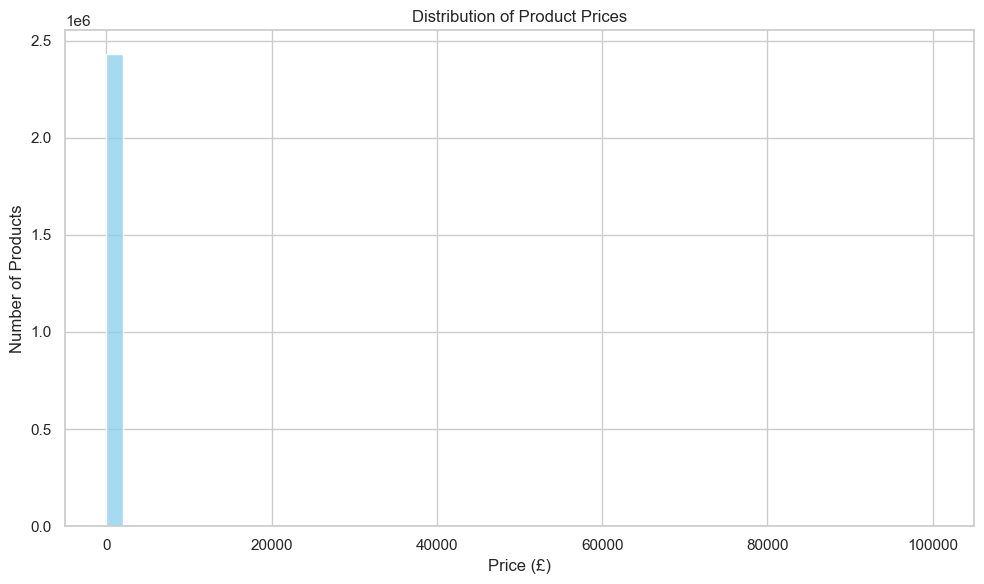

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean data
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

# Plot histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, color='skyblue')
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()


The chart shows a massive spike in products priced close to £0, and the count drops off dramatically as prices rise.

The x-axis ranges from £0 to £100,000, which compresses nearly all the meaningful data into the far-left side of the plot.

That single giant bar near £0 tells us that most products fall into a very low price range, possibly under £50.


Issue:

Scale distortion from extreme outliers (e.g., high-end luxury items or data errors) causes the bulk of prices to be crammed into one bin. As a result, subtle variations in typical pricing ranges are missed.

Solutions:
Cap the x-axis at a more realistic threshold like £500 or £1000 to better display the distribution of everyday products.
Use a log scale on the x-axis to reduce skewness from high-value outliers.
Add a secondary histogram zoomed into low-price ranges (e.g., £0–£100) for detailed insight.

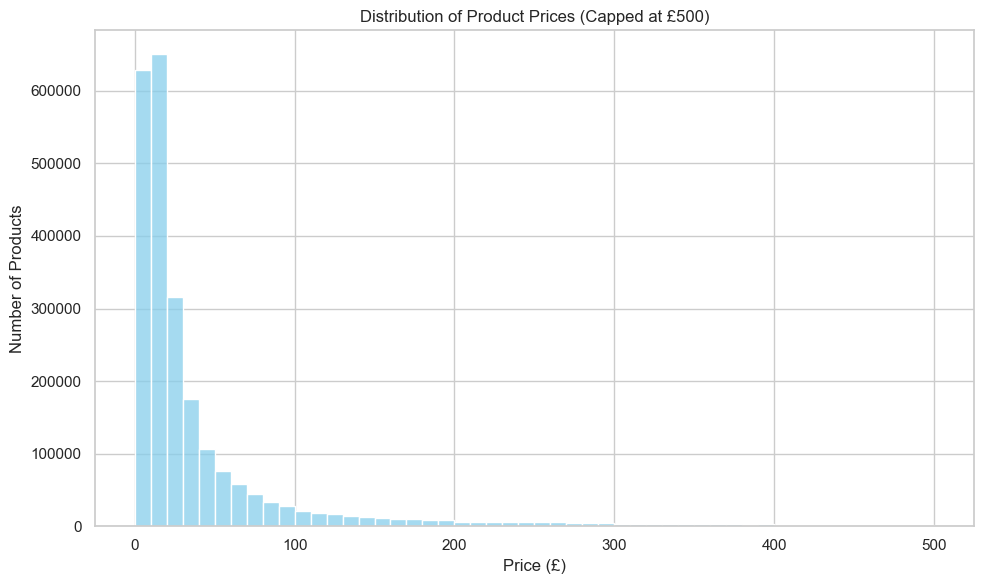

In [ ]:
# Product Prices Capped at £500
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean data
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

# Histogram for prices up to £500
plt.figure(figsize=(10, 6))
sns.histplot(df[df['price'] <= 500]['price'], bins=50, color='skyblue')
plt.title('Distribution of Product Prices (Capped at £500)')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()


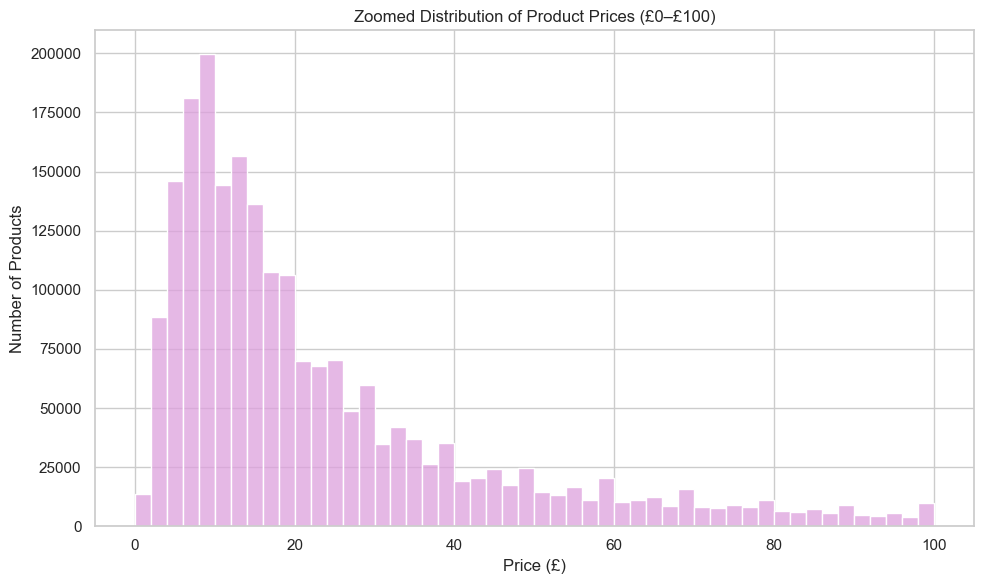

In [15]:
# Prices Between £0–£100
# Histogram for prices between £0 and £100
plt.figure(figsize=(10, 6))
sns.histplot(df[(df['price'] >= 0) & (df['price'] <= 100)]['price'], bins=50, color='plum')
plt.title('Zoomed Distribution of Product Prices (£0–£100)')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()



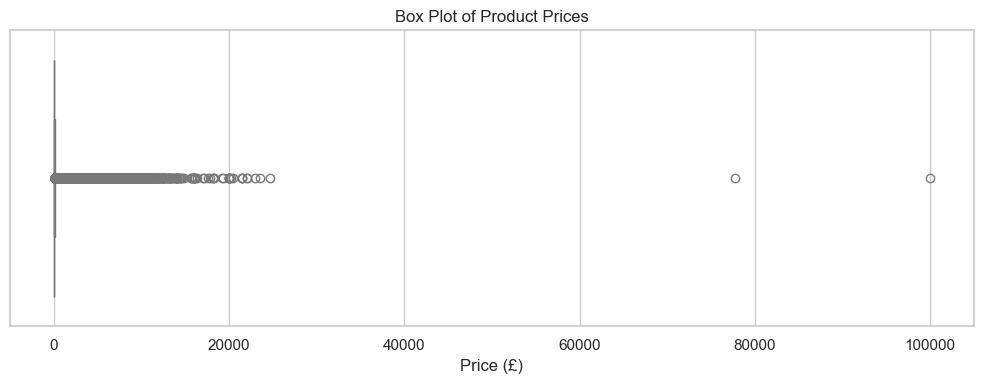

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean data
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

# Create box plot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'], color='lightblue')
plt.title('Box Plot of Product Prices')
plt.xlabel('Price (£)')
plt.tight_layout()
plt.show()


The majority of products are priced well below £20,000, with a dense clustering near the lower end.

A handful of products show up as extreme outliers — some priced around £80,000 to £100,000, which is highly atypical.

The skewness of the data is clear: prices stretch far to the right, indicating a long tail of high-ticket items.

Outliers like these can distort overall pricing analytics:

They may represent luxury goods, bundles, or even mispriced items.

If not filtered, they skew summary statistics (like average price) and can mislead forecasting models.


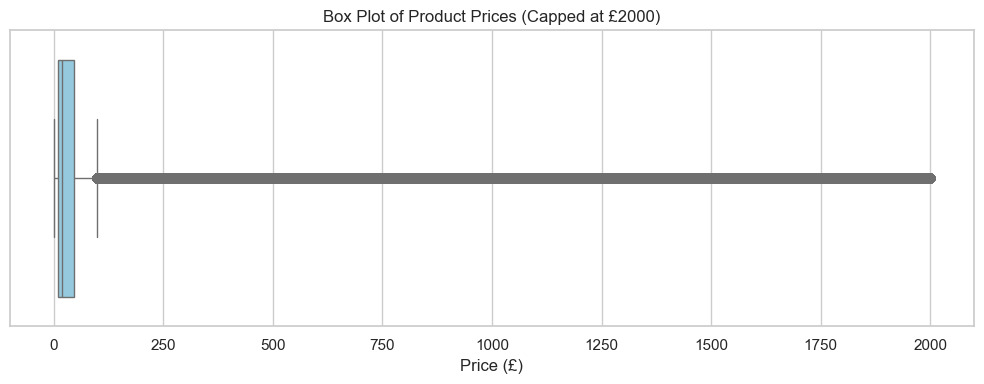

In [17]:
#Box Plot: Product Prices (Capped at £2000)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean data
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

# Filter prices up to £2000
filtered_df = df[df['price'] <= 2000]

# Create box plot
plt.figure(figsize=(10, 4))
sns.boxplot(x=filtered_df['price'], color='skyblue')
plt.title('Box Plot of Product Prices (Capped at £2000)')
plt.xlabel('Price (£)')
plt.tight_layout()
plt.show()



Dense clustering of prices at the lower end confirms that most products are priced under £500, with many under £100.

The box’s narrow width highlights a tight interquartile range, meaning the bulk of items fall into a relatively small price band.

Despite trimming extreme outliers, the whiskers and distant data points still reveal mid-level outliers, suggesting some products are pushing the £1000–£2000 boundary.


### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [18]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?



In [21]:
import pandas as pd

# Load dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# Drop missing ratings
ratings = df['stars'].dropna()

# Central tendency
mean_rating = ratings.mean()
median_rating = ratings.median()
mode_rating = ratings.mode().iloc[0] if not ratings.mode().empty else None

print("Mean Rating:", mean_rating)
print("Median Rating:", median_rating)
print("Mode Rating:", mode_rating)


Mean Rating: 2.152836472966065
Median Rating: 0.0
Mode Rating: 0.0


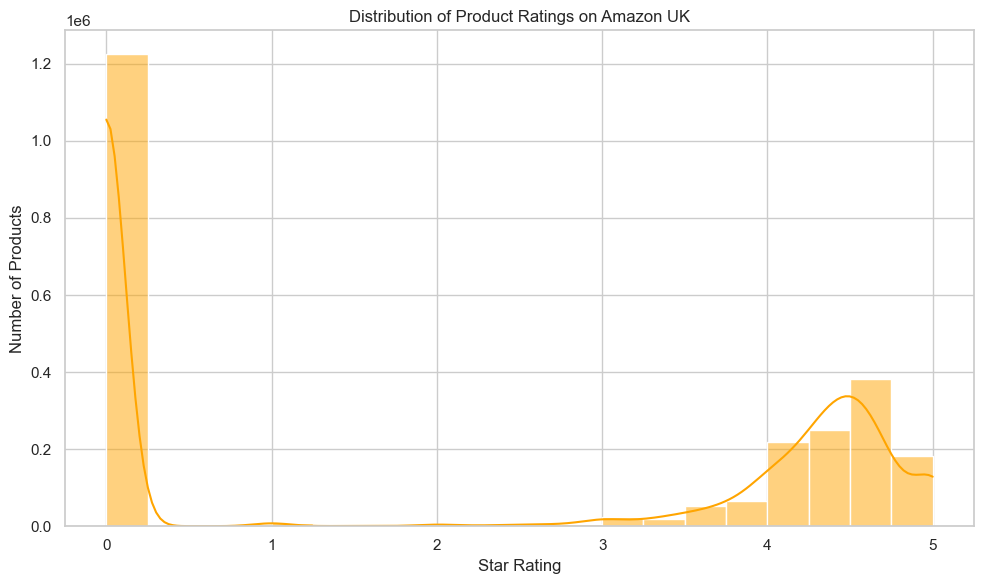

In [ ]:
# Measures of Centrality
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean data
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')
df = df.dropna(subset=['stars'])

# Plot histogram of ratings
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=20, kde=True, color='orange')
plt.title('Distribution of Product Ratings on Amazon UK')
plt.xlabel('Star Rating')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()


There’s a huge spike at a rating of 0 stars — suggesting a vast number of products lack any customer reviews.

Ratings between 1 and 3 stars are relatively rare, while 4 to 5 stars show a second peak, with 5 stars standing out.

This bimodal shape indicates:

Many products either haven’t been rated at all,

Or they’re rated very highly — a common phenomenon on platforms like Amazon.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?


In [22]:
#Measures of dispersion
# Dispersion metrics
variance = ratings.var()
std_dev = ratings.std()
iqr = ratings.quantile(0.75) - ratings.quantile(0.25)

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("Interquartile Range (IQR):", iqr)


Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
Interquartile Range (IQR): 4.4


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?



In [23]:
#Shape of distribution
from scipy.stats import skew, kurtosis

# Distribution shape
skewness = skew(ratings)
kurt = kurtosis(ratings)

print("Skewness:", skewness)
print("Kurtosis:", kurt)


Skewness: 0.08120730776283354
Kurtosis: -1.926004642549839



4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

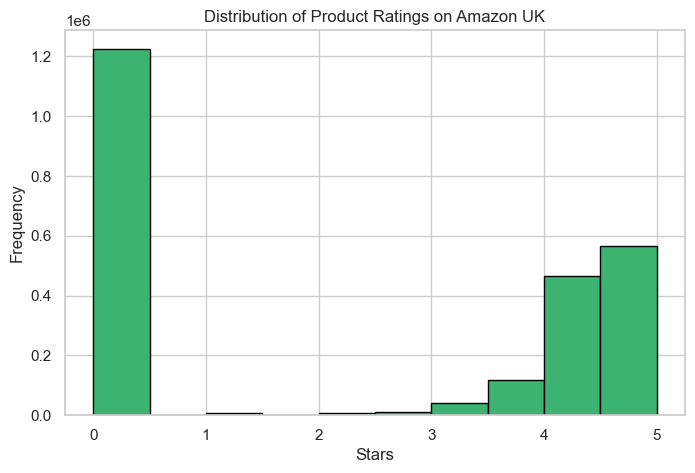

In [24]:
# Histogram visualisation

import matplotlib.pyplot as plt

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(ratings, bins=10, edgecolor='black', color='mediumseagreen')
plt.title('Distribution of Product Ratings on Amazon UK')
plt.xlabel('Stars')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


The most common rating is 0 stars, with a frequency of around 1.2 million.

This is followed by a noticeable peak at 5 stars, then gradually fewer ratings at 4, 3, 2, and 1 stars.
The bimodal distribution (peaks at 0 and 5) implies:
A large number of products may be unrated or have missing review data.

Many rated products tend to receive very high scores, possibly due to:
Positive bias in reviews,
Selective reviewing by satisfied customers.